## 1. Загрузка и преобразование изображения

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
from PIL import Image
import time

In [2]:
img = np.array(Image.open("funnycat.jpg"))
print(f"Размер изображения: {img.shape}")

R = img[:, :, 0].astype(np.float64)
G = img[:, :, 1].astype(np.float64)
B = img[:, :, 2].astype(np.float64)
channels = {"R": R, "G": G, "B": B}
print(f"Размер канала: {R.shape}")

Размер изображения: (1280, 922, 3)
Размер канала: (1280, 922)


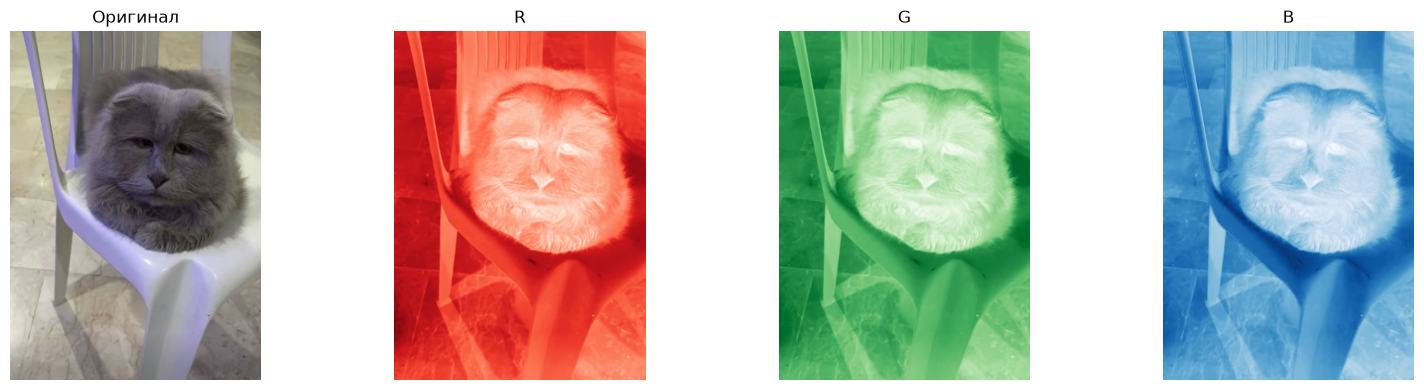

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img)
axes[0].set_title("Оригинал")
axes[1].imshow(R, cmap="Reds")
axes[1].set_title("R")
axes[2].imshow(G, cmap="Greens")
axes[2].set_title("G")
axes[3].imshow(B, cmap="Blues")
axes[3].set_title("B")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Степенной метод

### 2.1. Оценка числа операций **Степенной метод (одна компонента):**
- $A^T A$: матрица $m \times m$, каждый из $m^2$ элементов - скалярное произведение длины $n$ - $2nm^2$ операций
- $N$ итераций: умножение матрицы $(m \times m)$ на вектор - $2m^2$ каждое, итого $N \cdot 2m^2$
- $Av$: умножение матрицы $n \times m$ на вектор длины $m$ - $2nm$

Для $k$ компонент с дефляцией каждый раз пересчитываем $A^T A$ и np.outer c вычитанием стоит $2nm$:$$C_{\text{pow}}  = k \cdot (2nm^2 + N \cdot 2m^2 + 2nm) + k \cdot 2nm$$

In [4]:
def power_svd_truncated(A, k, num_iters):
    n, m = A.shape
    A_def = A.astype(np.float64).copy()
    U, S, Vt = [], [], []
    n_ops = 0

    for i in range(k):
        AtA = A_def.T @ A_def
        n_ops += 2*n*m*m

        v = np.ones(m)
        v = v / np.linalg.norm(v)
        for _ in range(num_iters):
            w = AtA @ v
            v = w / np.linalg.norm(w)
        n_ops += num_iters * 2*m*m

        Av = A_def @ v
        sigma = np.linalg.norm(Av)
        u = Av / sigma
        n_ops += 2*n*m

        U.append(u); S.append(sigma); Vt.append(v)

        A_def = A_def - sigma * np.outer(u, v)
        n_ops += 2*n*m

    return np.array(U).T, np.array(S), np.array(Vt), n_ops

### 2.2. Сравнение точности при $N \in \{10, 50, 100\}$
Выводится относительная норма $\|A - U \Sigma V^T\| / \|A\|$ для усечённого разложения с $k = 20$ компонент.

In [5]:
# Сравнение нормы восстановления при разных числах итераций N
k = 20
for name, A in channels.items():
    norm_A = np.linalg.norm(A)
    print(f"Канал {name}:")
    for N in [10, 50, 100]:
        U, S, Vt, _ = power_svd_truncated(A, k=k, num_iters=N)
        err = np.linalg.norm(A - U @ np.diag(S) @ Vt) / norm_A
        print(f"N={N}: norm = {err:.4f}")

Канал R:
N=10: norm = 0.0393
N=50: norm = 0.0392
N=100: norm = 0.0392
Канал G:
N=10: norm = 0.0408
N=50: norm = 0.0406
N=100: norm = 0.0406
Канал B:
N=10: norm = 0.0430
N=50: norm = 0.0430
N=100: norm = 0.0430


## 3. Сингулярные числа и усечённое SVD

### 3.1. Спектр сингулярных чисел
Считаем SVD один раз с $k = 60$ для всех каналов - этого достаточно и для графика спектра и для последующих экспериментвов при $k \in \{2, 5, 10, 20, 50\}$.

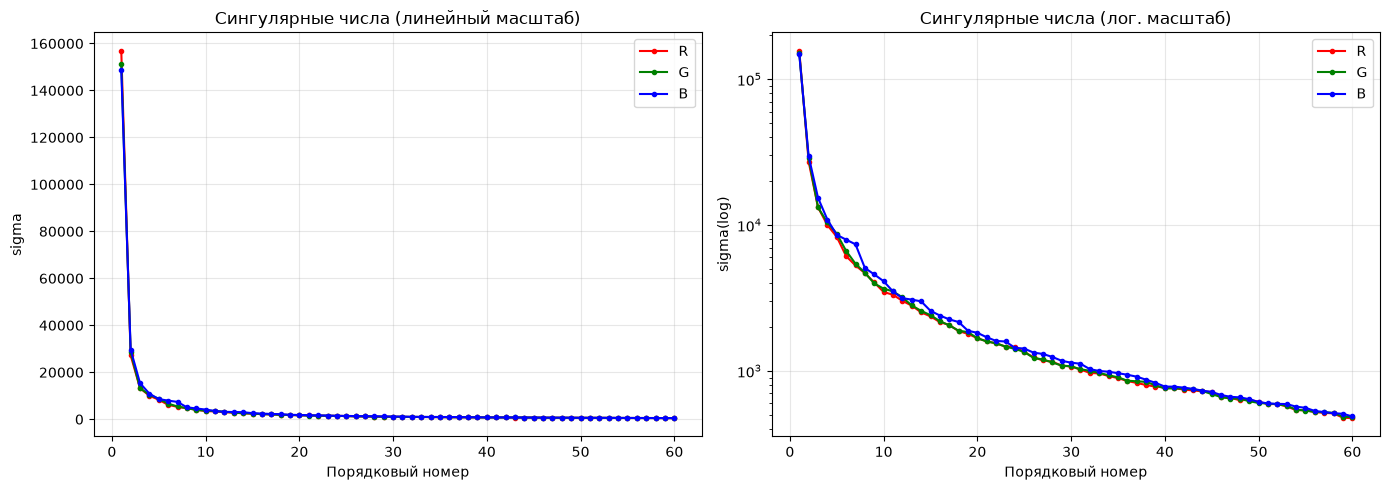

In [6]:
k = 60
n_iters = 100

channels_svd = {}
for name, A in channels.items():
    U_val, S_val, Vt_val, _ = power_svd_truncated(A, k=k, num_iters=n_iters)
    channels_svd[name] = (U_val, S_val, Vt_val)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = {"R": "red", "G": "green", "B": "blue"}
for name, (_, S, _) in channels_svd.items():
    axes[0].plot(range(1, len(S)+1), S, marker=".", color=colors[name], label=name)
    axes[1].semilogy(range(1, len(S)+1), S, marker=".", color=colors[name], label=name)

axes[0].set_title("Сингулярные числа (линейный масштаб)")
axes[0].set_xlabel("Порядковый номер")
axes[0].set_ylabel("sigma")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].set_title("Сингулярные числа (лог. масштаб)")
axes[1].set_xlabel("Порядковый номер")
axes[1].set_ylabel("sigma(log)")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.2. Предположение о $k$
На графике в логарифмическом масштабе виден резкий спад первых нескольких сингулярных чисел и плавный хвост.
Можно предположить, что для приемлемого качества восстановленного изображения достаточно $k$ порядка нескольких десятков. Проверим экспериментально на $k \in \{2, 5, 10, 20, 50\}$.

### 3.3. Восстановление при разных $k$

In [7]:
def reconstruct_image(channels_svd, k):
    """Собирает цветную картинку из усечённых матриц цветовых каналов"""

    rec = np.zeros((*channels["R"].shape, 3)) # 3-х мерный массив цветовых слоев

    for idx, name in enumerate(["R", "G", "B"]):
        U, S, Vt = channels_svd[name]
        rec[:, :, idx] = U[:, :k] @ np.diag(S[:k]) @ Vt[:k, :] # A_k = U_k S_k V_k^T
    rec = np.clip(rec, 0, 255).astype(np.uint8)
    return rec

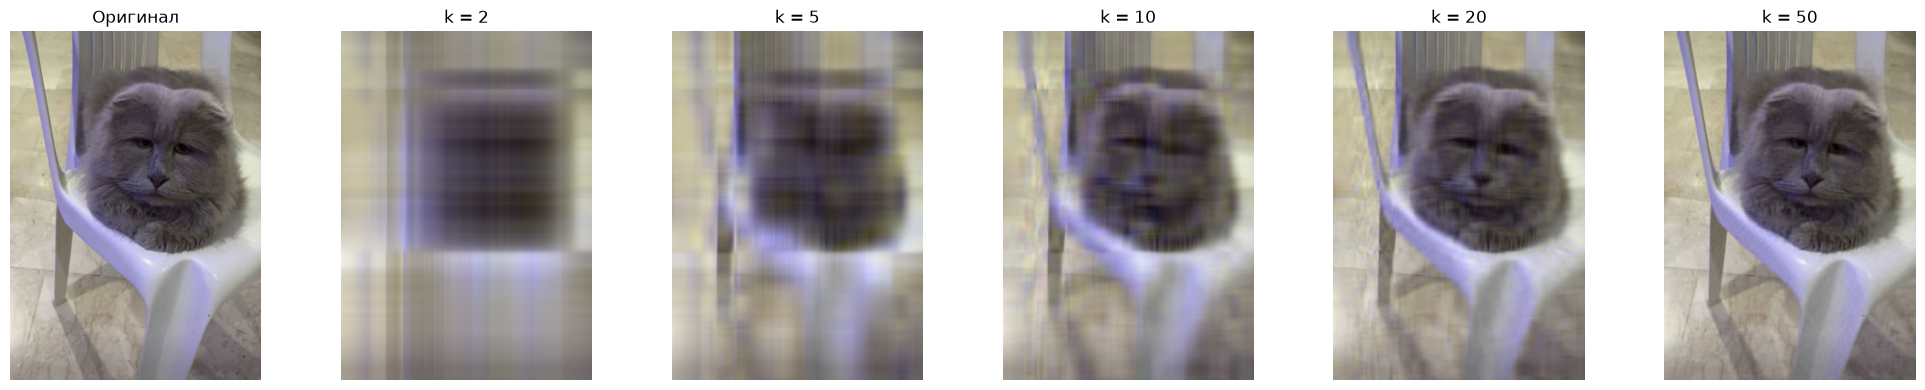

In [8]:
# Используем channels_svd, посчитанный в 3.1 (k=60), берём срезы до нужного k
k_values = [2, 5, 10, 20, 50]

fig, axes = plt.subplots(1, len(k_values) + 1, figsize=(20, 4))
axes[0].imshow(img)
axes[0].set_title("Оригинал")
axes[0].axis("off")

for i, k in enumerate(k_values):
    rec = reconstruct_image(channels_svd, k)
    axes[i + 1].imshow(rec)
    axes[i + 1].set_title(f"k = {k}")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

### 3.4. Степень сжатия данных

In [9]:
# Расчет кол-ва чисел для хранения после усеченного разложения и коэффициент сжатия
n, m = channels["R"].shape
print(f"Размер канала: {n}x{m} = {n*m} чисел на канал\n")
for k in [5, 10, 20, 50]:
    compressed = k * (n + m + 1)
    print(f"k={k}: {compressed} чисел, сжатие в {n*m/compressed:.1f} раз")

Размер канала: 1280x922 = 1180160 чисел на канал

k=5: 11015 чисел, сжатие в 107.1 раз
k=10: 22030 чисел, сжатие в 53.6 раз
k=20: 44060 чисел, сжатие в 26.8 раз
k=50: 110150 чисел, сжатие в 10.7 раз


## 4. Метод вращений Якоби

### 4.1. Оценка числа операций
- $A^T A$ - $2nm^2$ операций.

**Одна итерация:**
- Поиск максимального внедиагонального элемента: $\sim m^2$ операций (обход матрицы $m \times m$)
- Обновление строк $p$ и $q$: две строки длины $m$, по 2 умножения - $4m$
- Обновление столбцов $p$ и $q$: два столбца длины $m$, по 2 умножения - $4m$
Итого на одно вращение $\sim m^2 + 6m$ операций. За $k$ итераций:
$$C_{\text{jac}} = 2nm^2 + k \cdot (m^2 + 6m) \approx 2nm^2 + k m^2$$
При больших $k$ самым затратным становится поиск максимального элемента.

In [10]:
# Выбираем центральный блок картинки 200х200
H, W = channels["R"].shape
side = 200
y0 = (H - side) // 2
x0 = (W - side) // 2
A_block = channels["R"][y0:y0+side, x0:x0+side].copy()

# Эталон из numpy для проверки
s_ref = np.linalg.svd(A_block, compute_uv=False)
print("Топ 10 sigma:", np.round(s_ref[:10], 2))

Топ 10 sigma: [13683.13  1832.43  1472.98  1265.14   744.38   614.67   523.09   469.69
   414.73   402.62]


In [11]:
def jacobi_method(A, tol=1e-8, max_iter=200000):
    n, m = A.shape
    B = A.T @ A
    n_ops = 2*n*m*m

    norm_B = np.linalg.norm(B)

    for k in range(1, max_iter + 1):
        abs_B = np.abs(B)
        np.fill_diagonal(abs_B, 0)
        p, q = np.unravel_index(np.argmax(abs_B), B.shape) # Поиск максимального внедиагонального элемента
        n_ops += m*m

        # Остановка, если максимальный внедиагональный элемент мал относительно нормы Фробениуса
        if abs_B[p, q] / norm_B < tol:
            break

        if B[p, p] == B[q, q]:
            cos, sin = 1/np.sqrt(2), np.sign(B[p, q]) / np.sqrt(2)
        else:
            t = (2 * B[p, q]) / (B[p, p] - B[q, q])
            cos = np.sqrt(0.5 * (1 + 1 / np.sqrt(1 + t**2)))
            sin = np.sign(t) * np.sqrt(0.5 * (1 - 1 / np.sqrt(1 + t**2)))

        Bp = B[p, :].copy(); Bq = B[q, :].copy()
        B[p, :] =  cos*Bp + sin*Bq
        B[q, :] = -sin*Bp + cos*Bq
        Bp = B[:, p].copy(); Bq = B[:, q].copy()
        B[:, p] =  cos*Bp + sin*Bq
        B[:, q] = -sin*Bp + cos*Bq
        n_ops += 6*m

    # B положительно полуопределена, но численные ошибки вращений могут давать малые отрицательные значения на диагонали
    eigvals = np.maximum(np.diag(B), 0)
    sigmas = np.sort(np.sqrt(eigvals))[::-1]
    return sigmas, k, n_ops

### 4.2. Сравнение со степенным методом

In [12]:
# Якоби
t = time.time()
sigmas_jacobi, iters_jacobi, ops_jacobi = jacobi_method(A_block, tol=1e-6)
time_jacobi = time.time() - t

# Степенной
k_comp = 30
t = time.time()
U, S_power, Vt, ops_power = power_svd_truncated(A_block, k=k_comp, num_iters=100)
time_power = time.time() - t

print("Якоби:")
print(f"время: {time_jacobi:.3f} с, итераций: {iters_jacobi}, операций: {ops_jacobi:.2e}")

print(f"\nСтепенной (k={k_comp}):")
print(f"время: {time_power:.3f} с, операций: {ops_power:.2e}")

print(f"\nТоп 10 сингулярных чисел:")
print(f"Эталон:    {np.round(s_ref[:10], 2)}")
print(f"Якоби:     {np.round(sigmas_jacobi[:10], 2)}")
print(f"Степенной: {np.round(S_power[:10], 2)}")

print(f"\nМакс. ошибка по топ {k_comp} сингулярных чисел:")
print(f"Якоби:     {np.max(np.abs(sigmas_jacobi[:k_comp] - s_ref[:k_comp])):.2e}")
print(f"Степенной: {np.max(np.abs(S_power - s_ref[:k_comp])):.2e}")

# Степенной с k=200 (полный спектр)
t = time.time()
_, S_power_full, _, ops_power_full = power_svd_truncated(A_block, k=200, num_iters=100)
time_power_full = time.time() - t
print(f"\nСтепенной (k=200, полный спектр):")
print(f"время: {time_power_full:.3f} с, операций: {ops_power_full:.2e}")
print(f"Макс. ошибка: {np.max(np.abs(S_power_full - s_ref)):.2e}")

Якоби:
время: 0.307 с, итераций: 7765, операций: 3.36e+08

Степенной (k=30):
время: 0.010 с, операций: 7.25e+08

Топ 10 сингулярных чисел:
Эталон:    [13683.13  1832.43  1472.98  1265.14   744.38   614.67   523.09   469.69
   414.73   402.62]
Якоби:     [13683.13  1832.43  1472.98  1265.14   744.38   614.67   523.08   469.68
   414.73   402.61]
Степенной: [13683.13  1832.43  1472.98  1265.14   744.38   614.67   523.09   469.69
   414.73   402.62]

Макс. ошибка по топ 30 сингулярных чисел:
Якоби:     1.42e+00
Степенной: 1.06e-01

Степенной (k=200, полный спектр):
время: 0.066 с, операций: 4.83e+09
Макс. ошибка: 1.11e-01


## 5. Творческое задание

### 5.1. Гистограммы каналов

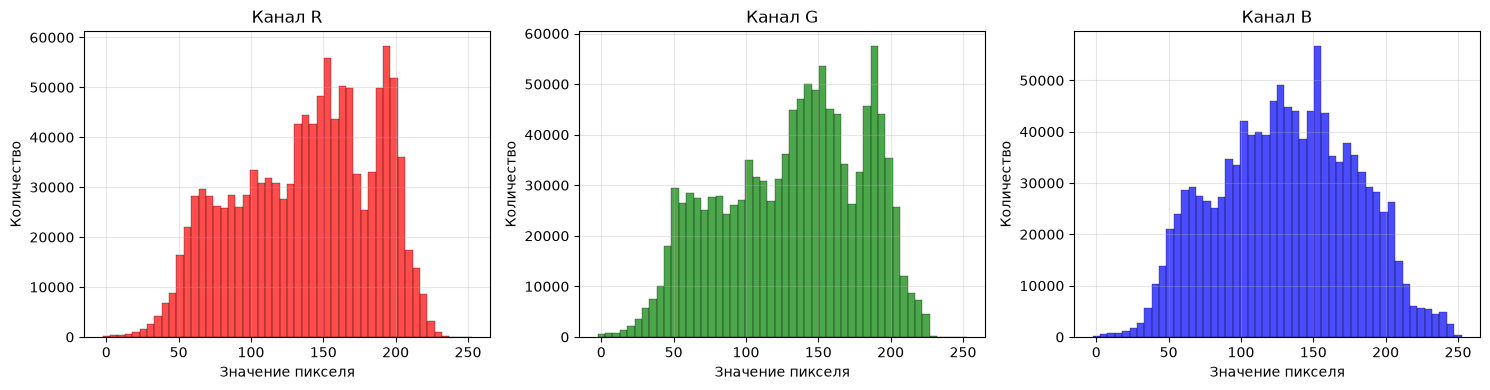

In [13]:
# Гистограммы распределения пикселей в каждом канале

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = {"R": "red", "G": "green", "B": "blue"}

for ax, (name, A) in zip(axes, channels.items()):
    counts, bins = np.histogram(A, bins=50, range=(0, 255))
    ax.bar(bins[:-1], counts, width=bins[1]-bins[0],
           color=colors[name], alpha=0.7, edgecolor="black", linewidth=0.3)
    ax.set_title(f"Канал {name}")
    ax.set_xlabel("Значение пикселя")
    ax.set_ylabel("Количество")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.2. Влияние SVD на распределение яркости

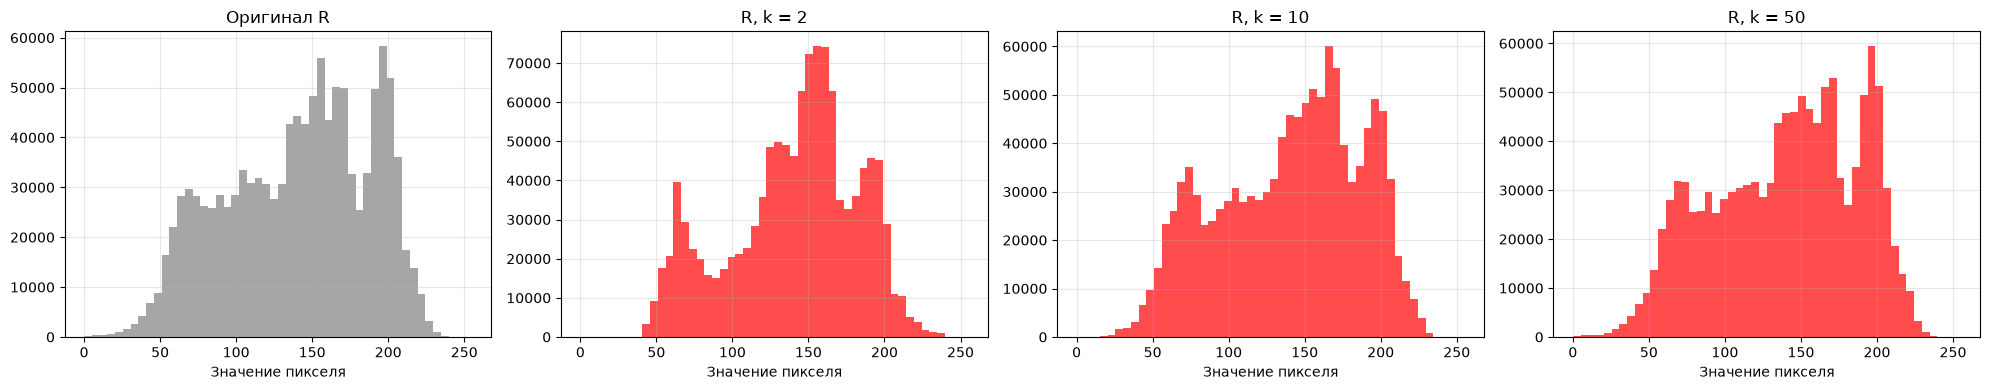

In [14]:
# Гистограммы распределения пикселей в восстановленных каналах R при разных k для анализа влияния усечения на распределения
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
k_compare = [2, 10, 50]

A_orig = channels["R"]
axes[0].hist(A_orig.ravel(), bins=50, range=(0, 255), color="gray", alpha=0.7)
axes[0].set_title("Оригинал R")
axes[0].set_xlabel("Значение пикселя")
axes[0].grid(True, alpha=0.3)

U, S, Vt = channels_svd["R"]
for i, k in enumerate(k_compare):
    A_rec = U[:, :k] @ np.diag(S[:k]) @ Vt[:k, :]
    A_rec = np.clip(A_rec, 0, 255)
    axes[i+1].hist(A_rec.ravel(), bins=50, range=(0, 255), color="red", alpha=0.7)
    axes[i+1].set_title(f"R, k = {k}")
    axes[i+1].set_xlabel("Значение пикселя")
    axes[i+1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3. Шумоподавление с помощью усечённого SVD

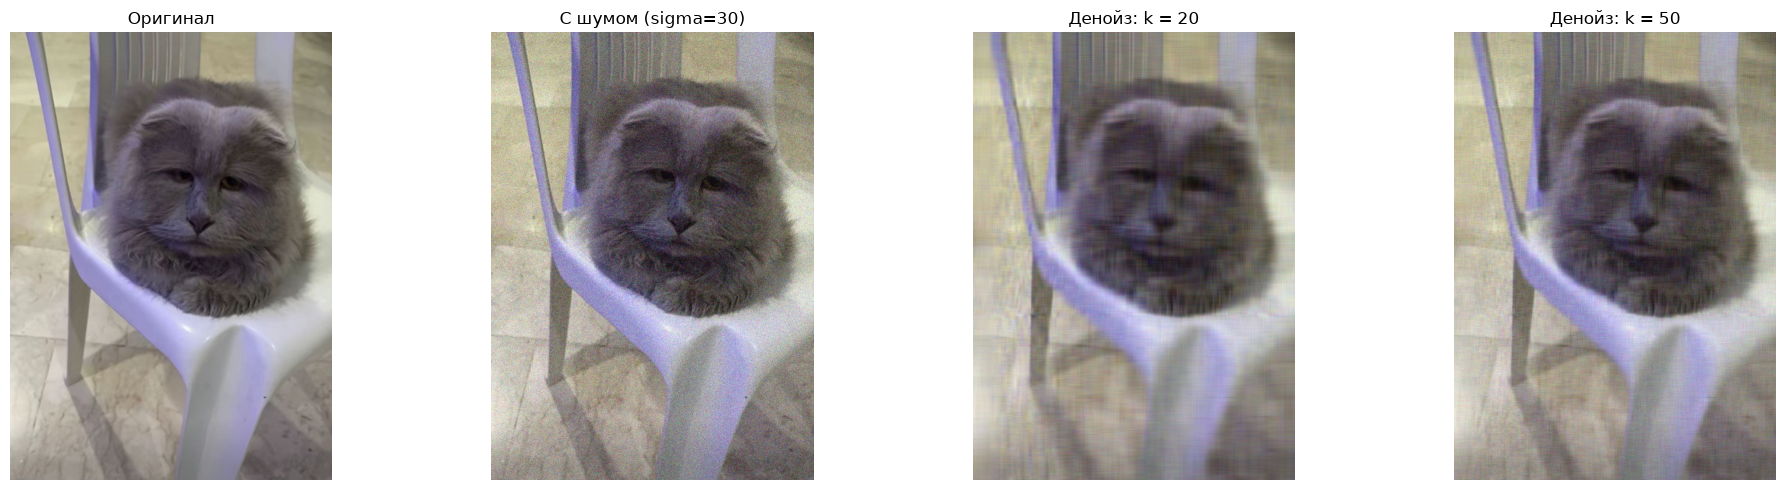

In [15]:
# Добавляем шум
np.random.seed(42)
noise_level = 30
img_noisy = img.astype(np.float64) + np.random.normal(0, noise_level, img.shape)
img_noisy = np.clip(img_noisy, 0, 255)

# Усеченный SVD для зашумленной картинки
def denoise(img_noisy, k, num_iters=50):
    rec = np.zeros_like(img_noisy)
    for idx in range(3):
        A_noisy = img_noisy[:, :, idx]
        U, S, Vt, _ = power_svd_truncated(A_noisy, k=k, num_iters=num_iters)
        rec[:, :, idx] = U @ np.diag(S) @ Vt
    return np.clip(rec, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img)
axes[0].set_title("Оригинал")

axes[1].imshow(img_noisy.astype(np.uint8))
axes[1].set_title(f"С шумом (sigma={noise_level})")

axes[2].imshow(denoise(img_noisy, k=20))
axes[2].set_title("Денойз: k = 20")
axes[3].imshow(denoise(img_noisy, k=50))

axes[3].set_title("Денойз: k = 50")
for ax in axes: ax.axis("off")

plt.tight_layout()
plt.show()

# Видно как зернистость шума исчезает и картинка становится более гладкой, хотя и визуально теряет в качестве